# Restaurant Ratings: Exploratory Analysis (Week 3)

**Data:** `fl_final_dataset.csv`, the cleaned and joined Yelp + Census + inspection data (one row per restaurant, Tampa Bay metro).

**Target:** `high_rating` = average Yelp rating of 4 stars or higher. `stars` (continuous) and `is_open` are the alternate targets.

Each research question has its own section, so each of us can keep the sections we own.

| Section | Research question |
|---|---|
| 1 | Which restaurant attributes are most strongly associated with a high rating? |
| 2 | Do neighborhood characteristics predict ratings after accounting for the restaurant's own attributes? |
| 3 | Is a restaurant's health inspection record related to its rating? |
| 4 | Do the drivers of a high rating differ by cuisine or by city? |
| 5 | Do the features that predict a high rating also predict whether a restaurant is still open? |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.neighbors import BallTree

pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 160)

# Consistent colors across every chart
BLUE, ORANGE, AQUA, YELLOW, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#8a8985'
DIVERGING = sns.blend_palette([BLUE, '#f0efec', ORANGE], as_cmap=True)

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'axes.titleweight': 'bold', 'axes.titlesize': 12,
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
})

df = pd.read_csv('fl_final_dataset.csv')
print(df.shape)
df.head()

(8731, 73)


,business_id,name,address,city,state,postal_code,metro,in_us,latitude,longitude,stars,high_rating,is_open,review_count,cuisine,categories,price_level,noise_level,outdoor_seating,delivery,takeout,alcohol,reservations,good_for_groups,good_for_kids,has_tv,wifi,attire,bike_parking,caters,table_service,wheelchair_accessible,happy_hour,dogs_allowed,accepts_credit_cards,drive_thru,noise_level_num,parking_garage,parking_street,parking_lot,parking_valet,parking_validated,meal_breakfast,meal_brunch,meal_lunch,meal_dinner,meal_dessert,meal_latenight,parking_any,ambience,num_categories,is_fast_food,is_bar,is_chain,days_open,open_weekend,open_late,zip,median_income,population,median_age,pct_college,ALAND_SQMI,pop_density,license_number,n_inspections,avg_violations,max_violations,avg_high_priority,avg_intermediate,avg_basic,name_score,has_inspection
0,eEOYSgkmpB90uNA7lDOMRA,Vietnamese Food Truck,NaN,Tampa Bay,FL,33602.0,Tampa,1,27.955269,-82.456320,4.0,1,1,10,Vietnamese,"Vietnamese, Food, Restaurants, Food Trucks",NaN,NaN,NaN,NaN,NaN,none,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,none_listed,4,0,0,0,7.0,1.0,0.0,33602.0,88878.0,17631.0,36.3,0.596544,2.592,6802.083333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,0bPLkL0QhhPO5kt1_EXmNQ,Zio's Italian Market,2575 E Bay Dr,Largo,FL,33771.0,Tampa,1,27.916116,-82.760461,4.5,1,0,100,Italian,"Food, Delis, Italian, Bakeries, Restaurants",1.0,average,0.0,1.0,1.0,none,0.0,0.0,1.0,1.0,no,casual,1.0,1.0,0.0,1.0,NaN,NaN,1.0,NaN,2.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,casual,5,0,0,0,6.0,1.0,0.0,33771.0,56275.0,28412.0,52.8,0.252015,5.992,4741.655541,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,uI9XODGY_2_ieTE6xJ0myw,Roman Forum,10440 N Dale Mabry Hwy,Tampa,FL,33618.0,Tampa,1,28.046203,-82.505053,4.0,1,0,23,Italian,"Restaurants, American (New), Italian",2.0,quiet,1.0,0.0,1.0,full_bar,1.0,1.0,1.0,1.0,no,casual,0.0,1.0,NaN,NaN,NaN,NaN,1.0,NaN,1.0,0.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,casual,3,0,0,0,6.0,1.0,1.0,33618.0,74016.0,28416.0,43.0,0.448289,8.466,3356.484763,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,JgpnXv_0XhV3SfbfB50nxw,Joe's Pizza,2038 N Dale Mabry Hwy,Tampa,FL,33607.0,Tampa,1,27.960514,-82.506127,4.0,1,0,35,Pizza,"Restaurants, Pizza",1.0,average,0.0,1.0,1.0,beer_and_wine,0.0,1.0,1.0,1.0,no,casual,1.0,0.0,NaN,NaN,NaN,NaN,1.0,NaN,2.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,casual,2,0,0,0,6.0,1.0,1.0,33607.0,57581.0,24257.0,40.7,0.331073,9.276,2615.028029,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,pJfh3Ct8iL58NZa8ta-a5w,Top Shelf Sports Lounge,3173 Cypress Ridge Blvd,Wesley Chapel,FL,33544.0,Tampa,1,28.196252,-82.380615,4.5,1,1,95,Burgers,"Burgers, Sports Bars, Bars, Lounges, Restauran...",2.0,average,0.0,1.0,1.0,full_bar,1.0,1.0,0.0,1.0,free,casual,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,casual,9,0,1,0,7.0,1.0,1.0,33544.0,98177.0,28472.0,36.8,0.441243,28.756,990.123800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


## 0. Overview of the data

In [2]:
print('Metros:', df['metro'].unique())
print(f"Restaurants: {len(df):,}")
print(f"Share highly rated (>= 4 stars): {df['high_rating'].mean():.1%}")
print(f"Share still open: {df['is_open'].mean():.1%}")
print(f"Share matched to an inspection record: {df['has_inspection'].mean():.1%}")

Metros: <StringArray>
['Tampa']
Length: 1, dtype: str
Restaurants: 8,731
Share highly rated (>= 4 stars): 48.0%
Share still open: 67.8%
Share matched to an inspection record: 42.7%


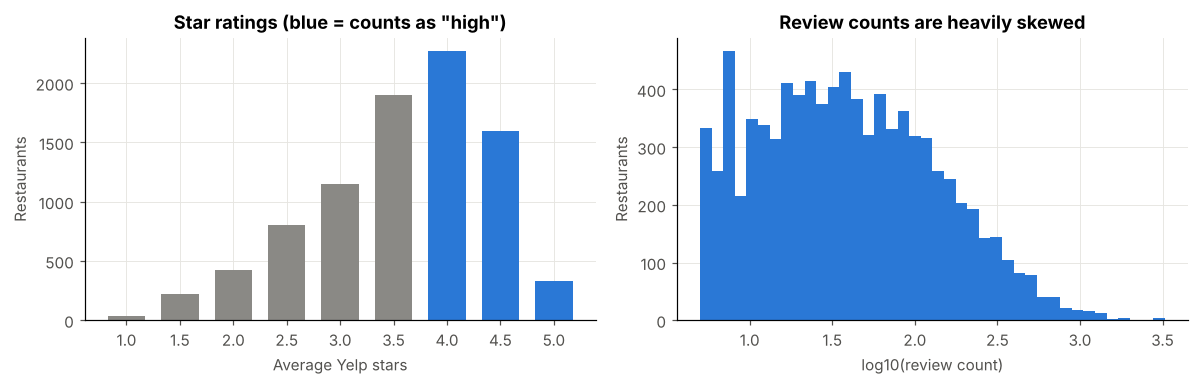

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

counts = df['stars'].value_counts().sort_index()
colors = [BLUE if s >= 4 else GRAY for s in counts.index]
axes[0].bar(counts.index.astype(str), counts.values, color=colors, width=0.7)
axes[0].set_title('Star ratings (blue = counts as "high")')
axes[0].set_xlabel('Average Yelp stars'); axes[0].set_ylabel('Restaurants')

axes[1].hist(np.log10(df['review_count']), bins=40, color=BLUE)
axes[1].set_title('Review counts are heavily skewed')
axes[1].set_xlabel('log10(review count)'); axes[1].set_ylabel('Restaurants')
plt.tight_layout(); plt.show()

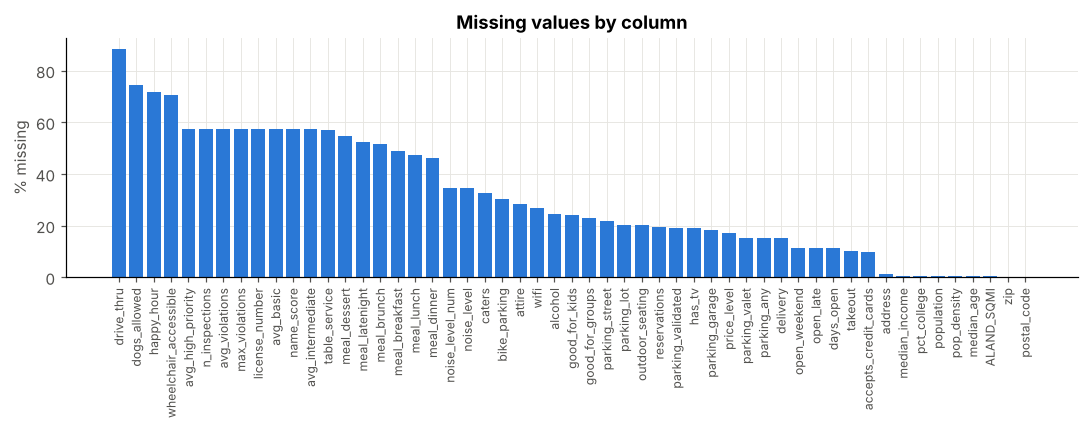

In [4]:
# Missing values: Yelp attributes are optional, so missingness is common
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(miss.index, miss.values * 100, color=BLUE)
ax.set_ylabel('% missing'); ax.set_title('Missing values by column')
plt.xticks(rotation=90, fontsize=8); plt.tight_layout(); plt.show()

In [5]:
# Is missingness itself informative? Restaurants that fill in more attributes may be better run.
attr_cols = ['price_level', 'noise_level', 'outdoor_seating', 'delivery', 'takeout', 'alcohol',
             'reservations', 'good_for_groups', 'good_for_kids', 'has_tv', 'wifi', 'attire',
             'bike_parking', 'caters', 'table_service', 'wheelchair_accessible', 'happy_hour',
             'dogs_allowed', 'accepts_credit_cards']
df['n_attrs_filled'] = df[attr_cols].notna().sum(axis=1)
df['attrs_bin'] = pd.cut(df['n_attrs_filled'], [-1, 5, 10, 14, 19], labels=['0-5', '6-10', '11-14', '15-19'])

t = df.groupby('attrs_bin', observed=True).agg(n=('high_rating', 'size'), pct_high=('high_rating', 'mean'),
                                              median_reviews=('review_count', 'median'))
t

,n,pct_high,median_reviews
attrs_bin,,,
0-5,1032,0.535853,11.0
6-10,1151,0.437011,16.0
11-14,2053,0.430589,21.0
15-19,4495,0.501446,82.0


**Note:** Restaurants with more attributes filled in tend to have more reviews. So in the sections below, "missing" is kept as its own category rather than dropped. Dropping it would quietly remove the smaller, less-reviewed restaurants.

In [6]:
# Helpers used throughout
OVERALL = df['high_rating'].mean()

def rate_table(data, col, target='high_rating', keep_missing=True):
    """Share with target == 1 for each level of col, with n and a 95% CI."""
    s = data[col].astype(object)
    if keep_missing:
        s = s.where(data[col].notna(), 'missing')
    g = data.groupby(s, observed=True)[target].agg(['size', 'mean'])
    g.columns = ['n', 'rate']
    g['ci'] = 1.96 * np.sqrt(g['rate'] * (1 - g['rate']) / g['n'])
    return g

def bar_rates(ax, table, title, order=None, baseline=OVERALL, min_n=30):
    t = table[table['n'] >= min_n]
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    colors = [GRAY if str(i) == 'missing' else BLUE for i in t.index]
    ax.bar([str(i) for i in t.index], t['rate'] * 100, yerr=t['ci'] * 100, color=colors,
           width=0.65, error_kw=dict(ecolor='#52514e', lw=1, capsize=3))
    ax.axhline(baseline * 100, ls='--', color='#52514e', lw=1)
    for i, (r, n) in enumerate(zip(t['rate'], t['n'])):
        ax.text(i, 2, f'n={n:,}', ha='center', fontsize=7, color='white')
    ax.set_title(title); ax.set_ylabel('% highly rated'); ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=30)

---
## 1. Which attributes are most strongly associated with a high rating?

Two views:
1. **Yes/no attributes:** the gap in % highly rated between restaurants that have the attribute and those that don't.
2. **Multi-level attributes** (price, noise, alcohol, ambience, parking): % highly rated at each level.

The dashed line on each chart is the overall rate (about 48%).

In [7]:
binary = ['outdoor_seating', 'delivery', 'takeout', 'reservations', 'good_for_groups', 'good_for_kids',
          'has_tv', 'bike_parking', 'caters', 'table_service', 'wheelchair_accessible', 'happy_hour',
          'dogs_allowed', 'accepts_credit_cards', 'drive_thru', 'parking_any', 'parking_lot',
          'parking_street', 'parking_valet', 'parking_garage', 'is_fast_food', 'is_bar', 'is_chain',
          'open_weekend', 'open_late']

def binary_effects(data, cols, target='high_rating', min_n=30):
    rows = []
    for c in cols:
        d = data[[c, target]].dropna()
        yes, no = d[d[c] == 1][target], d[d[c] == 0][target]
        if len(yes) < min_n or len(no) < min_n:
            continue
        p = stats.chi2_contingency(pd.crosstab(d[c], d[target]))[1]
        rows.append(dict(feature=c, rate_yes=yes.mean(), rate_no=no.mean(),
                         diff_pts=(yes.mean() - no.mean()) * 100, n_yes=len(yes), n_no=len(no), p_value=p))
    return pd.DataFrame(rows).sort_values('diff_pts')

eff = binary_effects(df, binary)
eff.sort_values('diff_pts', key=abs, ascending=False).round(3)

,feature,rate_yes,rate_no,diff_pts,n_yes,n_no,p_value
22,is_chain,0.122,0.585,-46.306,1966,6765,0.000
20,is_fast_food,0.134,0.529,-39.515,1081,7650,0.000
14,drive_thru,0.111,0.467,-35.538,620,405,0.000
24,open_late,0.388,0.646,-25.759,4498,3250,0.000
11,happy_hour,0.477,0.728,-25.061,1693,768,0.000
23,open_weekend,0.489,0.730,-24.041,7537,211,0.000
17,parking_street,0.677,0.440,23.740,1190,5633,0.000
6,has_tv,0.451,0.598,-14.622,5577,1489,0.000
8,caters,0.555,0.414,14.099,3763,2109,0.000
0,outdoor_seating,0.520,0.406,11.373,3882,3080,0.000


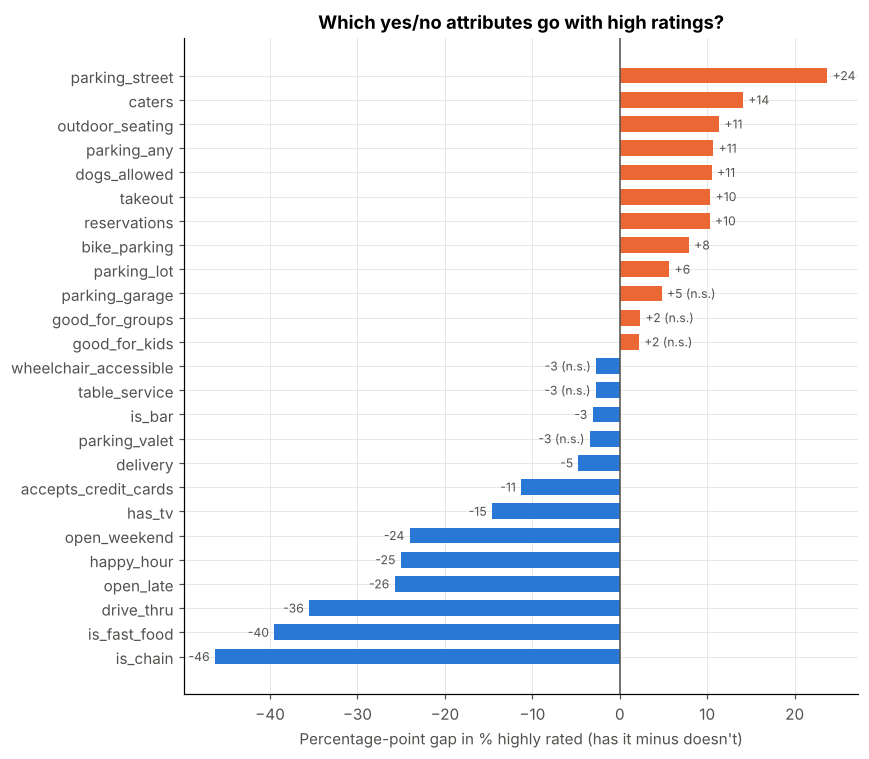

In [8]:
fig, ax = plt.subplots(figsize=(8, 7))
colors = [ORANGE if v > 0 else BLUE for v in eff['diff_pts']]
ax.barh(eff['feature'], eff['diff_pts'], color=colors, height=0.65)
ax.axvline(0, color='#52514e', lw=1)
for y, (v, p) in enumerate(zip(eff['diff_pts'], eff['p_value'])):
    ax.text(v + (0.6 if v > 0 else -0.6), y, f'{v:+.0f}' + ('' if p < 0.05 else ' (n.s.)'),
            va='center', ha='left' if v > 0 else 'right', fontsize=8, color='#52514e')
ax.set_xlabel('Percentage-point gap in % highly rated (has it minus doesn\'t)')
ax.set_title('Which yes/no attributes go with high ratings?')
plt.tight_layout(); plt.show()

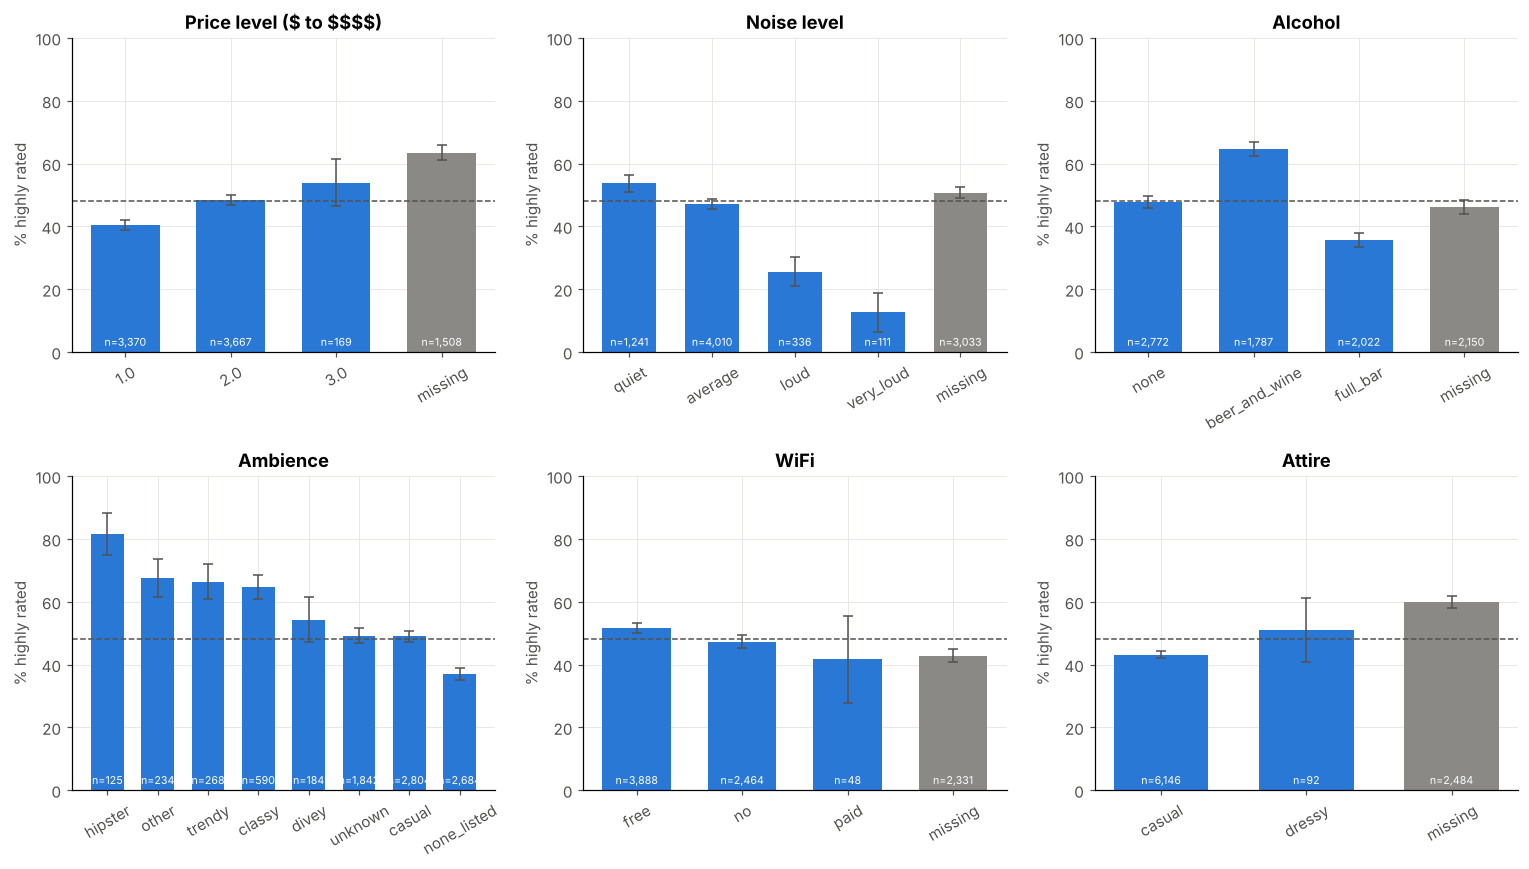

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
bar_rates(axes[0, 0], rate_table(df, 'price_level'), 'Price level ($ to $$$$)', order=[1.0, 2.0, 3.0, 4.0, 'missing'])
bar_rates(axes[0, 1], rate_table(df, 'noise_level'), 'Noise level', order=['quiet', 'average', 'loud', 'very_loud', 'missing'])
bar_rates(axes[0, 2], rate_table(df, 'alcohol'), 'Alcohol', order=['none', 'beer_and_wine', 'full_bar', 'missing'])
amb = rate_table(df, 'ambience').sort_values('rate', ascending=False)
bar_rates(axes[1, 0], amb, 'Ambience')
bar_rates(axes[1, 1], rate_table(df, 'wifi'), 'WiFi', order=['free', 'no', 'paid', 'missing'])
bar_rates(axes[1, 2], rate_table(df, 'attire'), 'Attire', order=['casual', 'dressy', 'formal', 'missing'])
plt.tight_layout(); plt.show()

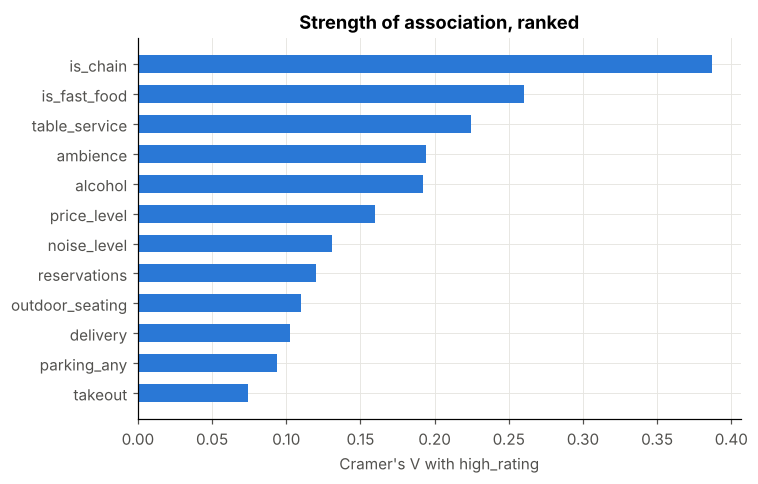

is_chain           0.387
is_fast_food       0.260
table_service      0.224
ambience           0.194
alcohol            0.192
price_level        0.160
noise_level        0.131
reservations       0.120
outdoor_seating    0.110
delivery           0.103
parking_any        0.094
takeout            0.074
dtype: float64

In [10]:
# One number per attribute to rank them: Cramer's V (0 = no association, 1 = perfect).
# Missing is kept as its own level so every restaurant counts.
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

rq1_cols = ['price_level', 'noise_level', 'ambience', 'outdoor_seating', 'delivery', 'takeout',
            'alcohol', 'parking_any', 'reservations', 'table_service', 'is_chain', 'is_fast_food']
assoc = pd.Series({c: cramers_v(df[c].astype(object).fillna('missing'), df['high_rating']) for c in rq1_cols})
assoc = assoc.sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(assoc.index, assoc.values, color=BLUE, height=0.6)
ax.set_xlabel("Cramer's V with high_rating"); ax.set_title('Strength of association, ranked')
plt.tight_layout(); plt.show()
assoc.sort_values(ascending=False).round(3)

**Takeaways (RQ1):**
- **Being a chain or fast food is the strongest signal by far.** Only 12% of chains are highly rated vs 59% of independents (Cramer's V = 0.39, about 1.5x the next attribute).
- **Noise:** 54% of quiet restaurants are highly rated vs 13% of very loud ones.
- **Alcohol:** beer & wine only does best (65%), and a full bar does worst (36%).
- **Ambience:** hipster, trendy and classy places sit at 65–82%.
- **Price** rises modestly with level, from 40% at \$ to 54% at \$\$\$.
- **Street parking** is +24 pts, probably standing in for walkable urban locations.
- **Open late, happy hour and TVs** all go with lower ratings (−15 to −26 pts). That's the sports-bar/chain profile.
- **Missing price** is 64% highly rated, well above any listed price level. These are often small, newer independents, so keep "missing" as a level in the models.

---
## 2. Do neighborhood characteristics predict ratings beyond the restaurant's own attributes?

Neighborhood features: ZIP-level `median_income`, `pop_density`, `pct_college` and `median_age` from the Census, plus **local competition**, which is computed here as the number of other restaurants in the dataset within 1 km.

Approach:
1. Look at the raw relationships (% highly rated by quintile).
2. Fit two logistic regressions: **A** = the restaurant's own attributes only, **B** = A + neighborhood. Then check whether B fits meaningfully better (likelihood-ratio test, pseudo-R², AUC).

In [11]:
# Local competition: restaurants within 1 km (haversine distance on lat/lon)
EARTH_R_KM = 6371.0
coords = np.radians(df[['latitude', 'longitude']].values)
tree = BallTree(coords, metric='haversine')

df['competitors_1km'] = tree.query_radius(coords, r=1.0 / EARTH_R_KM, count_only=True) - 1  # minus itself

# Same-cuisine competitors within 1 km
idx = tree.query_radius(coords, r=1.0 / EARTH_R_KM)
cuis = df['cuisine'].values
df['same_cuisine_1km'] = [int((cuis[i] == cuis[k]).sum()) - 1 for k, i in enumerate(idx)]

df[['competitors_1km', 'same_cuisine_1km']].describe().round(1)

,competitors_1km,same_cuisine_1km
count,8731.0,8731.0
mean,43.2,3.0
std,45.8,4.0
min,0.0,0.0
25%,16.0,0.0
50%,30.0,2.0
75%,52.0,4.0
max,265.0,29.0


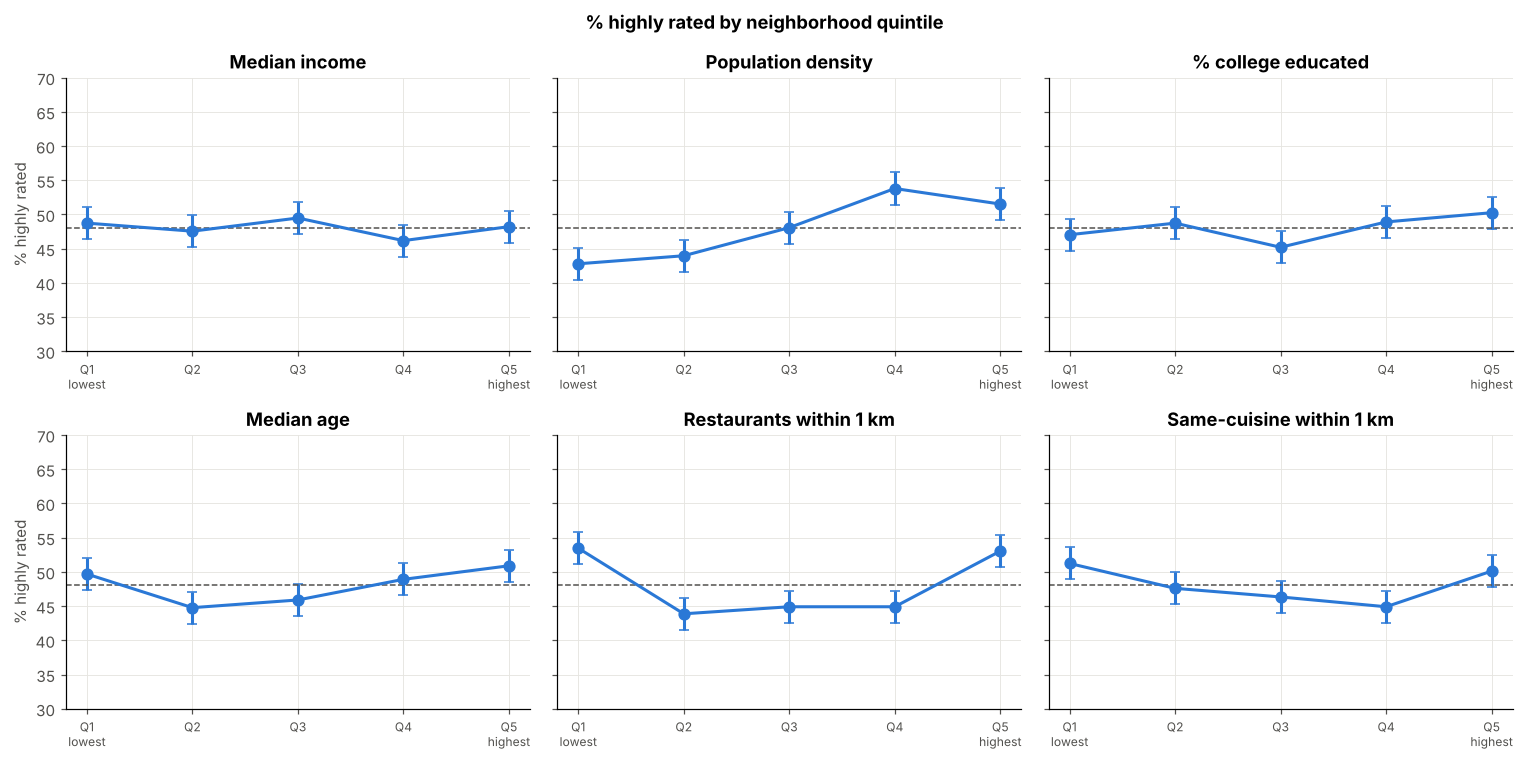

In [12]:
nbhd = ['median_income', 'pop_density', 'pct_college', 'median_age', 'competitors_1km', 'same_cuisine_1km']
labels = {'median_income': 'Median income', 'pop_density': 'Population density', 'pct_college': '% college educated',
          'median_age': 'Median age', 'competitors_1km': 'Restaurants within 1 km', 'same_cuisine_1km': 'Same-cuisine within 1 km'}

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, c in zip(axes.flat, nbhd):
    q = pd.qcut(df[c].rank(method='first'), 5, labels=['Q1\nlowest', 'Q2', 'Q3', 'Q4', 'Q5\nhighest'])
    t = df.groupby(q, observed=True)['high_rating'].agg(['mean', 'size'])
    ci = 1.96 * np.sqrt(t['mean'] * (1 - t['mean']) / t['size'])
    ax.errorbar(range(5), t['mean'] * 100, yerr=ci * 100, color=BLUE, marker='o', ms=7, lw=2, capsize=3)
    ax.axhline(OVERALL * 100, ls='--', color='#52514e', lw=1)
    ax.set_xticks(range(5)); ax.set_xticklabels(t.index, fontsize=8)
    ax.set_title(labels[c]); ax.set_ylim(30, 70)
axes[0, 0].set_ylabel('% highly rated'); axes[1, 0].set_ylabel('% highly rated')
plt.suptitle('% highly rated by neighborhood quintile', fontweight='bold'); plt.tight_layout(); plt.show()

In [13]:
# Spearman correlations with stars (continuous target)
pd.DataFrame({c: stats.spearmanr(df[c], df['stars'], nan_policy='omit') for c in nbhd},
             index=['rho', 'p_value']).T.round(4)

,rho,p_value
median_income,0.0086,0.4252
pop_density,0.0955,0.0000
pct_college,0.0430,0.0001
median_age,0.0348,0.0012
competitors_1km,0.0078,0.4660
same_cuisine_1km,-0.0177,0.0989


In [14]:
# Build a modeling frame. Categorical attributes keep 'missing' as a level.
own_cat = ['price_level', 'noise_level', 'alcohol', 'ambience', 'outdoor_seating', 'delivery', 'takeout',
           'parking_any', 'reservations', 'table_service']
own_num = ['is_chain', 'is_fast_food', 'is_bar', 'open_late', 'log_reviews']

m = df.copy()
m['log_reviews'] = np.log1p(m['review_count'])
for c in own_cat:
    m[c] = m[c].astype(object).where(m[c].notna(), 'missing').astype(str)
for c in ['open_late']:
    m[c] = m[c].fillna(0)

# Standardize neighborhood vars so coefficients are comparable (per 1 SD)
for c in nbhd:
    m[c + '_z'] = (m[c] - m[c].mean()) / m[c].std()
m['log_density_z'] = np.log1p(m['pop_density']); m['log_density_z'] = (m['log_density_z'] - m['log_density_z'].mean()) / m['log_density_z'].std()

m = m.dropna(subset=['median_income', 'pop_density', 'pct_college', 'median_age'])
print(f'Rows used in models: {len(m):,} of {len(df):,}')

own_terms = ' + '.join([f'C({c})' for c in own_cat] + own_num)
nb_terms = 'median_income_z + log_density_z + pct_college_z + median_age_z + competitors_1km_z + same_cuisine_1km_z'

model_a = smf.logit(f'high_rating ~ {own_terms}', data=m).fit(disp=0)
model_b = smf.logit(f'high_rating ~ {own_terms} + {nb_terms}', data=m).fit(disp=0)

Rows used in models: 8,698 of 8,731


In [15]:
from sklearn.metrics import roc_auc_score

lr = 2 * (model_b.llf - model_a.llf)
df_diff = model_b.df_model - model_a.df_model
p_lr = stats.chi2.sf(lr, df_diff)

print(f'Likelihood-ratio test: chi2={lr:.1f}, df={df_diff:.0f}, p={p_lr:.2g}')
pd.DataFrame({
    'Model A: own attributes': [model_a.prsquared, roc_auc_score(m['high_rating'], model_a.predict(m)), model_a.aic],
    'Model B: + neighborhood': [model_b.prsquared, roc_auc_score(m['high_rating'], model_b.predict(m)), model_b.aic],
}, index=['McFadden pseudo-R2', 'AUC (in-sample)', 'AIC']).round(4)

Likelihood-ratio test: chi2=19.6, df=6, p=0.0033


,Model A: own attributes,Model B: + neighborhood
McFadden pseudo-R2,0.2490,0.2506
AUC (in-sample),0.8180,0.8191
AIC,9117.8552,9110.2809


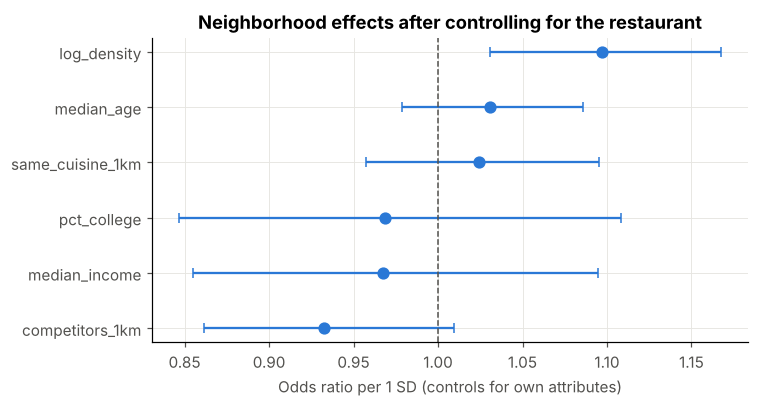

,odds_ratio,ci_low,ci_high,p_value
competitors_1km_z,0.932,0.861,1.009,0.083
median_income_z,0.967,0.855,1.095,0.598
pct_college_z,0.969,0.847,1.108,0.643
same_cuisine_1km_z,1.024,0.958,1.095,0.486
median_age_z,1.031,0.979,1.086,0.249
log_density_z,1.097,1.031,1.167,0.004


In [16]:
# Neighborhood effects in Model B, shown as odds ratios per 1 SD
nb_vars = [v for v in model_b.params.index if v.endswith('_z')]
orr = pd.DataFrame({'odds_ratio': np.exp(model_b.params[nb_vars]),
                    'ci_low': np.exp(model_b.conf_int().loc[nb_vars, 0]),
                    'ci_high': np.exp(model_b.conf_int().loc[nb_vars, 1]),
                    'p_value': model_b.pvalues[nb_vars]}).sort_values('odds_ratio')

fig, ax = plt.subplots(figsize=(7, 3.8))
y = range(len(orr))
ax.errorbar(orr['odds_ratio'], y, xerr=[orr['odds_ratio'] - orr['ci_low'], orr['ci_high'] - orr['odds_ratio']],
            fmt='o', color=BLUE, ms=7, capsize=3, lw=1.5)
ax.axvline(1, color='#52514e', ls='--', lw=1)
ax.set_yticks(list(y)); ax.set_yticklabels([v.replace('_z', '') for v in orr.index])
ax.set_xlabel('Odds ratio per 1 SD (controls for own attributes)')
ax.set_title('Neighborhood effects after controlling for the restaurant')
plt.tight_layout(); plt.show()
orr.round(3)

**Takeaways (RQ2):**
- **The neighborhood adds almost nothing once the restaurant's own attributes are known.** Pseudo-R² goes from 0.249 to 0.251 and AUC from 0.818 to 0.819.
- The likelihood-ratio test is significant (p = 0.003), but **population density** drives it alone (OR 1.10 per SD).
- Income, education, median age and local competition are all non-significant after controls.
- Competition within 1 km leans slightly negative (OR 0.93, p = 0.08).

---
## 3. Is the health inspection record related to the rating?

Only part of the restaurants matched to an inspection record (`has_inspection`). First check whether the matched ones differ from the rest, since that affects how far the results generalize. Then, among the matched restaurants, compare violations with ratings.

In [17]:
# Who got matched? If matched restaurants differ a lot, results only describe that subset.
df.groupby('has_inspection').agg(n=('stars', 'size'), pct_high=('high_rating', 'mean'), mean_stars=('stars', 'mean'),
                                 pct_open=('is_open', 'mean'), median_reviews=('review_count', 'median'),
                                 pct_chain=('is_chain', 'mean')).round(3)

,n,pct_high,mean_stars,pct_open,median_reviews,pct_chain
has_inspection,,,,,,
False,5001,0.456,3.562,0.448,26.0,0.166
True,3730,0.513,3.601,0.987,59.0,0.304


In [18]:
insp = df[df['has_inspection']].copy()
print(f'Matched restaurants: {len(insp):,}')
print(insp['name_score'].describe().round(1))

# Keep only confident name matches for the analysis below (change the cutoff if the cleaning used a different one)
NAME_CUTOFF = 85
insp = insp[insp['name_score'] >= NAME_CUTOFF]
print(f'After name_score >= {NAME_CUTOFF}: {len(insp):,}')

insp_vars = ['n_inspections', 'avg_violations', 'max_violations', 'avg_high_priority', 'avg_intermediate', 'avg_basic']
insp[insp_vars].describe().round(2)

Matched restaurants: 3,730
count    3730.0
mean       98.8
std         3.6
min        80.0
25%       100.0
50%       100.0
75%       100.0
max       100.0
Name: name_score, dtype: float64
After name_score >= 85: 3,634


,n_inspections,avg_violations,max_violations,avg_high_priority,avg_intermediate,avg_basic
count,3634.00,3634.00,3634.00,3634.00,3634.00,3634.00
mean,1.73,8.00,9.54,1.54,1.74,4.72
std,0.49,4.83,5.99,1.43,1.36,3.17
min,1.00,0.00,0.00,0.00,0.00,0.00
25%,1.00,4.50,5.00,0.50,1.00,2.50
50%,2.00,7.00,8.00,1.00,1.50,4.00
75%,2.00,10.50,13.00,2.00,2.50,6.00
max,5.00,46.00,49.00,13.00,11.00,24.50


In [19]:
# Spearman correlation of each inspection measure with stars (rank-based, so robust to skew)
pd.DataFrame({c: stats.spearmanr(insp[c], insp['stars'], nan_policy='omit') for c in insp_vars},
             index=['rho', 'p_value']).T.round(4)

,rho,p_value
n_inspections,0.1918,0.000
avg_violations,0.0842,0.000
max_violations,0.1104,0.000
avg_high_priority,0.1643,0.000
avg_intermediate,0.1649,0.000
avg_basic,-0.0198,0.232


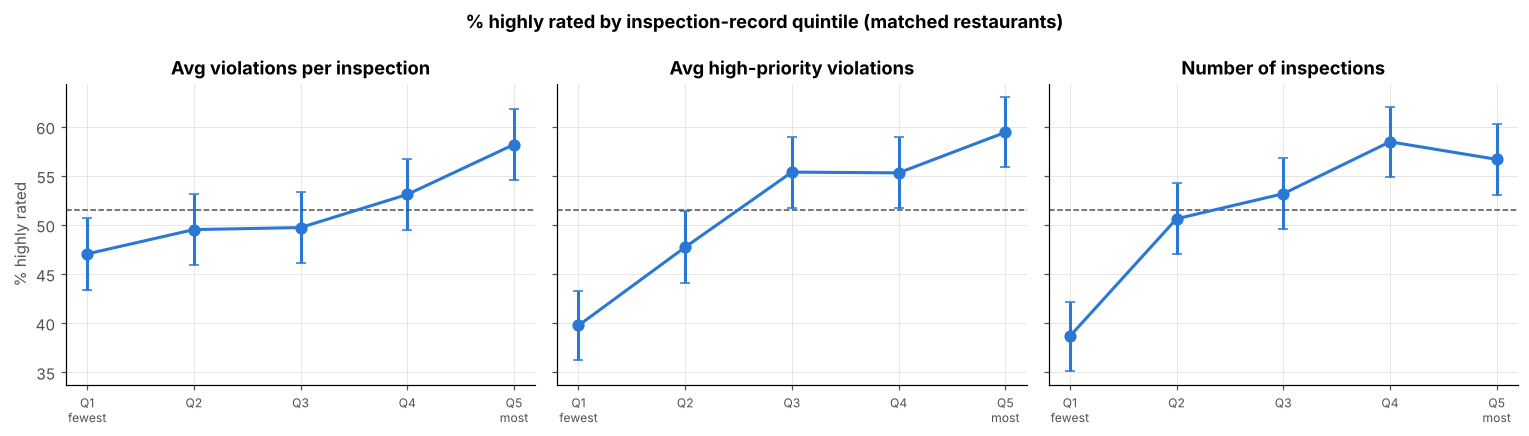

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, c, title in zip(axes, ['avg_violations', 'avg_high_priority', 'n_inspections'],
                        ['Avg violations per inspection', 'Avg high-priority violations', 'Number of inspections']):
    q = pd.qcut(insp[c].rank(method='first'), 5, labels=['Q1\nfewest', 'Q2', 'Q3', 'Q4', 'Q5\nmost'])
    t = insp.groupby(q, observed=True)['high_rating'].agg(['mean', 'size'])
    ci = 1.96 * np.sqrt(t['mean'] * (1 - t['mean']) / t['size'])
    ax.errorbar(range(5), t['mean'] * 100, yerr=ci * 100, color=BLUE, marker='o', ms=7, lw=2, capsize=3)
    ax.axhline(insp['high_rating'].mean() * 100, ls='--', color='#52514e', lw=1)
    ax.set_xticks(range(5)); ax.set_xticklabels(t.index, fontsize=8); ax.set_title(title)
axes[0].set_ylabel('% highly rated')
plt.suptitle('% highly rated by inspection-record quintile (matched restaurants)', fontweight='bold')
plt.tight_layout(); plt.show()

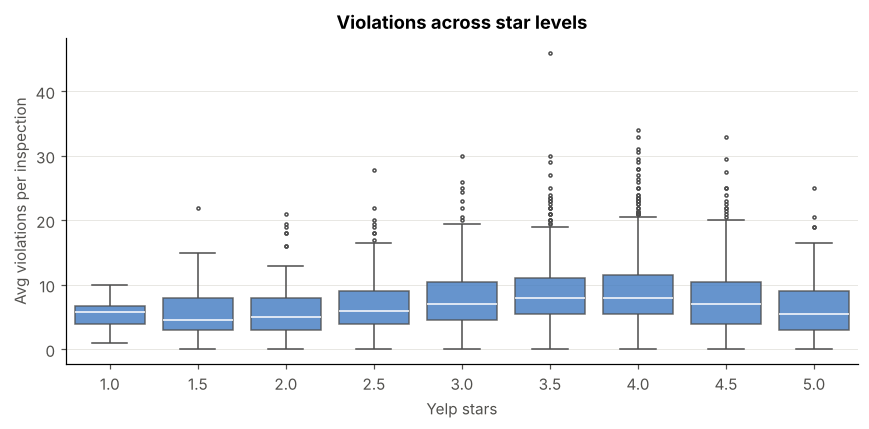

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=insp, x='stars', y='avg_violations', color=BLUE, fliersize=2, ax=ax,
            boxprops=dict(alpha=0.8), medianprops=dict(color='white'))
ax.set_xlabel('Yelp stars'); ax.set_ylabel('Avg violations per inspection')
ax.set_title('Violations across star levels')
plt.tight_layout(); plt.show()

In [22]:
# Does the inspection record still matter once we control for the restaurant's own attributes?
mi = m[m['business_id'].isin(insp['business_id'])].copy()
for c in ['avg_violations', 'avg_high_priority']:
    mi[c + '_z'] = (mi[c] - mi[c].mean()) / mi[c].std()

model_i = smf.logit(f'high_rating ~ {own_terms} + avg_violations_z + avg_high_priority_z', data=mi).fit(disp=0)
ivars = ['avg_violations_z', 'avg_high_priority_z']
pd.DataFrame({'odds_ratio_per_SD': np.exp(model_i.params[ivars]), 'p_value': model_i.pvalues[ivars]}).round(4)

,odds_ratio_per_SD,p_value
avg_violations_z,0.8095,0.0005
avg_high_priority_z,1.1392,0.0293


**Takeaways (RQ3):**
- **Big selection issue:** 98.7% of matched restaurants are still open, vs 45% of unmatched ones. Inspection records only cover currently licensed restaurants, so these results describe open restaurants only. **Do not use `has_inspection` as a feature for `is_open`.** It would leak the answer.
- The raw correlations are *positive*: more inspections and more high-priority violations go with slightly higher stars (rho ≈ 0.16–0.19). Busy independent kitchens likely get inspected more often and cited more.
- After controlling for the restaurant's own attributes, **average violations are negatively related to a high rating** (OR 0.81 per SD, p < 0.001). High-priority violations stay slightly positive (OR 1.14, p = 0.03).
- Overall the relationship is weak and mixed, so inspections are a minor predictor.

---
## 4. Do the drivers of a high rating differ by cuisine or city?

The cleaned data covers **one metro (Tampa Bay)**, so "city" here means municipalities inside it (Tampa, St. Petersburg, Clearwater, ...). Comparing metros would need the other Yelp states.

The heatmaps show the percentage-point gap from Section 1 (has the attribute minus doesn't), computed separately within each cuisine or city. Blank cells have fewer than 30 restaurants on one side.

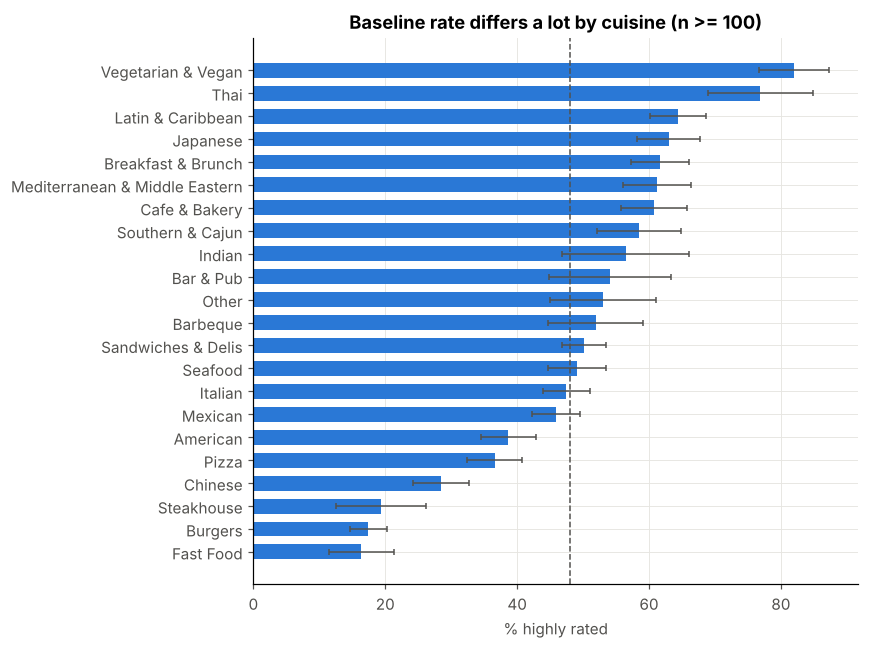

In [23]:
cu = rate_table(df, 'cuisine', keep_missing=False)
cu = cu[cu['n'] >= 100].sort_values('rate')

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(cu.index, cu['rate'] * 100, xerr=cu['ci'] * 100, color=BLUE, height=0.65,
        error_kw=dict(ecolor='#52514e', lw=1, capsize=2))
ax.axvline(OVERALL * 100, ls='--', color='#52514e', lw=1)
ax.set_xlabel('% highly rated'); ax.set_title('Baseline rate differs a lot by cuisine (n >= 100)')
plt.tight_layout(); plt.show()

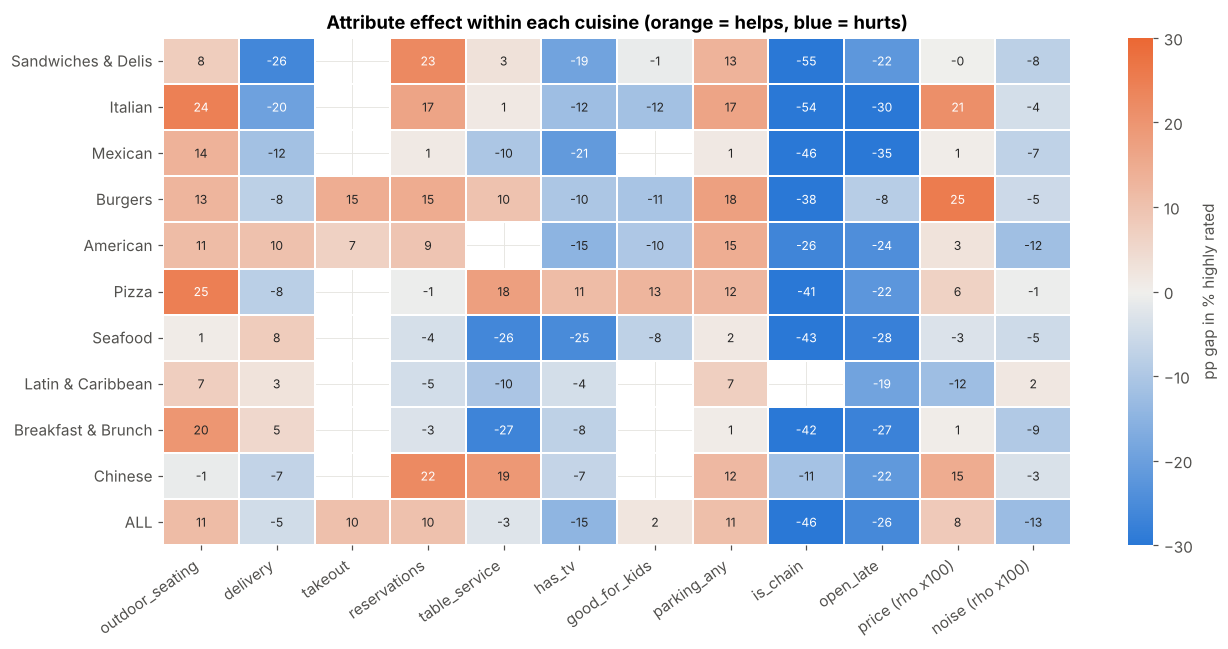

In [24]:
heat_feats = ['outdoor_seating', 'delivery', 'takeout', 'reservations', 'table_service', 'has_tv',
              'good_for_kids', 'parking_any', 'is_chain', 'open_late']

def effect_grid(data, group_col, groups, feats, min_n=30):
    out = pd.DataFrame(index=groups, columns=feats, dtype=float)
    for g in groups:
        sub = data[data[group_col] == g]
        for f in feats:
            d = sub[[f, 'high_rating']].dropna()
            yes, no = d[d[f] == 1]['high_rating'], d[d[f] == 0]['high_rating']
            if len(yes) >= min_n and len(no) >= min_n:
                out.loc[g, f] = (yes.mean() - no.mean()) * 100
    return out

def add_price_noise(grid, data, group_col):
    # Ordinal attributes as Spearman rho x 100, so they fit the same color scale roughly
    for col, name in [('price_level', 'price (rho x100)'), ('noise_level_num', 'noise (rho x100)')]:
        grid[name] = [stats.spearmanr(*data.loc[data[group_col] == g, [col, 'high_rating']].dropna().T.values)[0] * 100
                      if data.loc[data[group_col] == g, col].notna().sum() >= 60 else np.nan for g in grid.index]
    return grid

top_cuisines = df['cuisine'].value_counts().head(10).index.tolist()
grid_c = add_price_noise(effect_grid(df, 'cuisine', top_cuisines, heat_feats), df, 'cuisine')
grid_c.loc['ALL'] = list(effect_grid(df.assign(_all='ALL'), '_all', ['ALL'], heat_feats).loc['ALL']) + \
                    [stats.spearmanr(*df[[c, 'high_rating']].dropna().T.values)[0] * 100 for c in ['price_level', 'noise_level_num']]

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(grid_c.astype(float), cmap=DIVERGING, center=0, vmin=-30, vmax=30, annot=True, fmt='.0f',
            annot_kws=dict(size=8), linewidths=1, linecolor='white', cbar_kws=dict(label='pp gap in % highly rated'), ax=ax)
ax.set_title('Attribute effect within each cuisine (orange = helps, blue = hurts)')
ax.set_xlabel(''); ax.set_ylabel('')
plt.xticks(rotation=35, ha='right'); plt.tight_layout(); plt.show()

                     n   rate     ci
city                                
Riverview          199  0.402  0.068
Brandon            327  0.407  0.053
New Port Richey    227  0.423  0.064
Largo              312  0.474  0.055
Clearwater         679  0.480  0.038
Palm Harbor        208  0.500  0.068
Tampa             2967  0.501  0.018
Saint Petersburg  1017  0.515  0.031


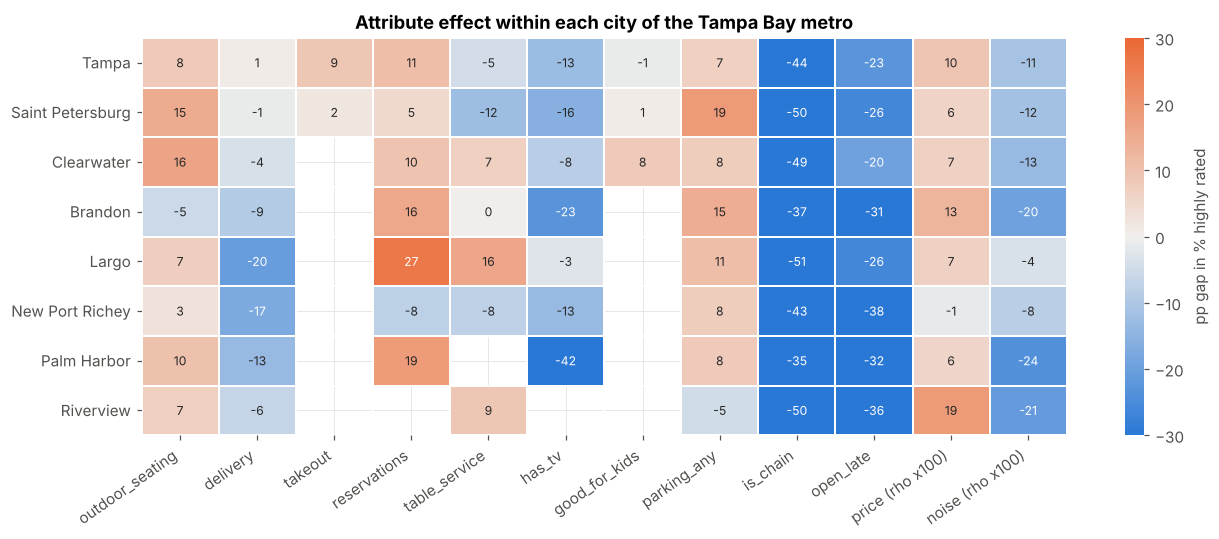

In [25]:
top_cities = df['city'].value_counts().head(8).index.tolist()
ci_rates = rate_table(df[df['city'].isin(top_cities)], 'city', keep_missing=False).sort_values('rate')
print(ci_rates.round(3))

grid_city = add_price_noise(effect_grid(df, 'city', top_cities, heat_feats), df, 'city')
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(grid_city.astype(float), cmap=DIVERGING, center=0, vmin=-30, vmax=30, annot=True, fmt='.0f',
            annot_kws=dict(size=8), linewidths=1, linecolor='white', cbar_kws=dict(label='pp gap in % highly rated'), ax=ax)
ax.set_title('Attribute effect within each city of the Tampa Bay metro')
ax.set_xlabel(''); ax.set_ylabel('')
plt.xticks(rotation=35, ha='right'); plt.tight_layout(); plt.show()

In [26]:
# Formal check for one example: does the effect of price differ by cuisine? (interaction LR test)
mc = m[m['cuisine'].isin(top_cuisines)].copy()
mc['price_num'] = pd.to_numeric(mc['price_level'], errors='coerce')
mc = mc.dropna(subset=['price_num'])
base = smf.logit('high_rating ~ price_num + C(cuisine) + log_reviews', data=mc).fit(disp=0)
inter = smf.logit('high_rating ~ price_num * C(cuisine) + log_reviews', data=mc).fit(disp=0)
lr_i = 2 * (inter.llf - base.llf); dfi = inter.df_model - base.df_model
print(f'Price x cuisine interaction: chi2={lr_i:.1f}, df={dfi:.0f}, p={stats.chi2.sf(lr_i, dfi):.3g}')

Price x cuisine interaction: chi2=45.4, df=9, p=7.77e-07


**Takeaways (RQ4):**
- **The baseline differs a lot by cuisine.** Vegetarian/vegan (82%), Thai (77%) and Latin/Caribbean (64%) are at the top. Fast food (16%), burgers (17%) and steakhouses (19%) are at the bottom.
- **Some effects are universal.** Being a chain hurts in every cuisine, and being open late hurts in nearly all of them.
- **Others change direction.** Outdoor seating helps Italian, pizza and brunch places (+20–25 pts) but does nothing for seafood or Chinese. Delivery hurts delis and Italian (−20 to −26) but not seafood or American. Higher price helps burgers, Italian and Chinese but not Latin/Caribbean.
- The price × cuisine interaction is significant (p < 0.001). So a model should include cuisine interactions or use trees.
- **Cities:** rates range from 40% (Riverview, Brandon) to 52% (St. Petersburg). The data covers only the Tampa Bay metro, so comparing metros isn't possible with this file.

---
## 5. Do the same features predict staying open?

Compute the same percentage-point gap twice for each feature, once for `high_rating` and once for `is_open`, and plot them against each other. Points on the diagonal help (or hurt) both outcomes equally.

**Caveat:** `is_open` is a snapshot from when Yelp built the dataset, and some closures predate the reviews. Treat this as association, not survival.

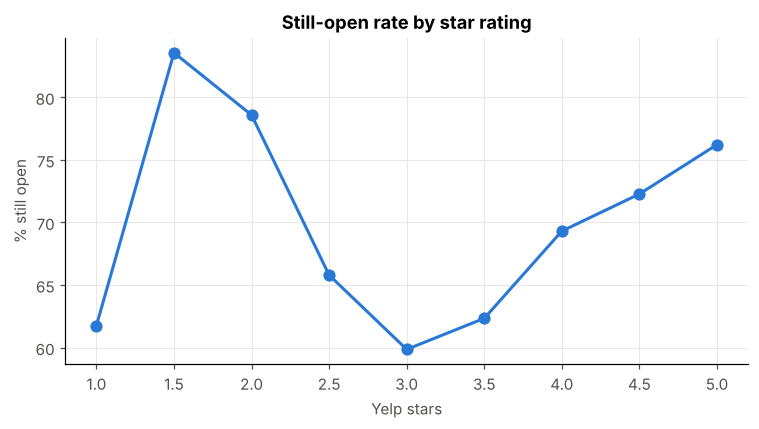

is_open          0      1
high_rating              
0            0.351  0.649
1            0.290  0.710


In [27]:
fig, ax = plt.subplots(figsize=(7, 4))
t = df.groupby('stars')['is_open'].agg(['mean', 'size'])
ax.plot(t.index, t['mean'] * 100, marker='o', color=BLUE, lw=2, ms=7)
ax.set_xlabel('Yelp stars'); ax.set_ylabel('% still open'); ax.set_title('Still-open rate by star rating')
plt.tight_layout(); plt.show()
print(pd.crosstab(df['high_rating'], df['is_open'], normalize='index').round(3))

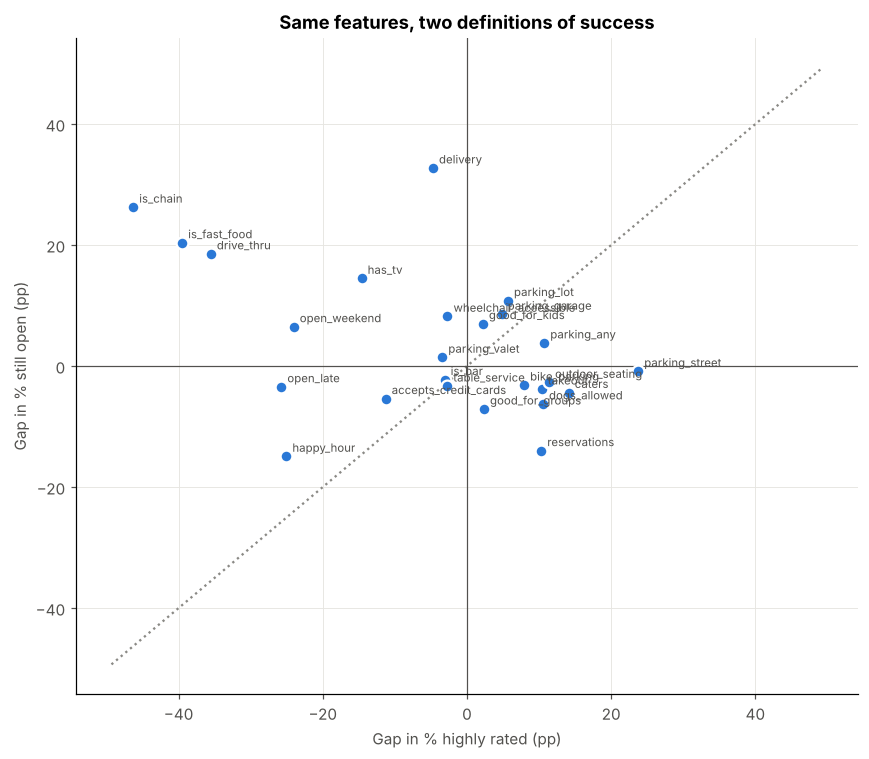

Spearman correlation between the two sets of effects: rho=-0.39, p=0.053


,high_rating_gap,is_open_gap
feature,,
happy_hour,-25.1,-14.9
reservations,10.3,-14.0
good_for_groups,2.4,-7.1
dogs_allowed,10.5,-6.3
accepts_credit_cards,-11.3,-5.4
caters,14.1,-4.4
takeout,10.4,-3.8
open_late,-25.8,-3.4
table_service,-2.7,-3.3


In [28]:
eff_r = binary_effects(df, binary, 'high_rating').set_index('feature')['diff_pts']
eff_o = binary_effects(df, binary, 'is_open').set_index('feature')['diff_pts']
both = pd.concat([eff_r.rename('high_rating_gap'), eff_o.rename('is_open_gap')], axis=1).dropna()

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(both['high_rating_gap'], both['is_open_gap'], color=BLUE, s=60, edgecolor='white', lw=1.5, zorder=3)
for f, r in both.iterrows():
    ax.annotate(f, (r['high_rating_gap'], r['is_open_gap']), xytext=(4, 3), textcoords='offset points', fontsize=7.5, color='#52514e')
lim = max(both.abs().max()) + 3
ax.plot([-lim, lim], [-lim, lim], ls=':', color=GRAY)
ax.axhline(0, color='#52514e', lw=0.8); ax.axvline(0, color='#52514e', lw=0.8)
ax.set_xlabel('Gap in % highly rated (pp)'); ax.set_ylabel('Gap in % still open (pp)')
ax.set_title('Same features, two definitions of success')
plt.tight_layout(); plt.show()

rho, p = stats.spearmanr(both['high_rating_gap'], both['is_open_gap'])
print(f'Spearman correlation between the two sets of effects: rho={rho:.2f}, p={p:.3f}')
both.sort_values('is_open_gap').round(1)

In [29]:
# Same own-attribute model as Section 2, refit for is_open, plus stars as a predictor
model_o = smf.logit(f'is_open ~ {own_terms} + stars', data=m).fit(disp=0)
print(f"AUC is_open model: {roc_auc_score(m['is_open'], model_o.predict(m)):.3f}")
print(f"Odds ratio per extra star: {np.exp(model_o.params['stars']):.2f} (p={model_o.pvalues['stars']:.2g})")

comp = pd.DataFrame({'high_rating_coef': model_a.params, 'is_open_coef': model_o.params}).dropna()
comp = comp.drop('Intercept')
comp['same_direction'] = np.sign(comp['high_rating_coef']) == np.sign(comp['is_open_coef'])
print(f"Coefficients pointing the same way in both models: {comp['same_direction'].mean():.0%}")
comp.round(3)

AUC is_open model: 0.829
Odds ratio per extra star: 1.28 (p=9.3e-09)
Coefficients pointing the same way in both models: 43%


,high_rating_coef,is_open_coef,same_direction
C(alcohol)[T.full_bar],-1.380,0.064,False
C(alcohol)[T.missing],-0.257,0.412,False
C(alcohol)[T.none],0.122,0.331,True
C(ambience)[T.classy],0.481,1.065,True
C(ambience)[T.divey],0.234,-0.108,False
C(ambience)[T.hipster],1.235,-0.285,False
C(ambience)[T.none_listed],-0.071,0.392,False
C(ambience)[T.other],0.647,0.442,True
C(ambience)[T.trendy],0.534,-0.351,False
C(ambience)[T.unknown],0.001,0.685,True


**Takeaways (RQ5):**
- **Mostly no: the features often point the opposite way.** The two sets of effects are negatively correlated (rho = −0.39), and only 43% of model coefficients share a sign.
- Chains, fast food and drive-thrus are much *less* likely to be highly rated but *more* likely to still be open (+19 to +26 pts).
- Delivery is +33 pts for staying open, likely because the delivery attribute was added to Yelp profiles recently. That makes it a marker of being alive at snapshot time (possible leakage).
- **Ratings still help a bit:** 71% of highly rated restaurants are open vs 65% of the rest, and each star raises the odds of being open by 28% after controls.

---
## Summary of findings
1. **What predicts a high rating** is mostly *what kind of restaurant it is*: independent vs chain, cuisine, noise, alcohol type and ambience.
2. **Neighborhood** barely adds anything beyond the restaurant itself, apart from a small boost from population density.
3. **Inspections** are weakly and inconsistently related to ratings, and only cover open restaurants.
4. **Drivers differ by cuisine** (significant interactions), so tree models or cuisine interactions are worth trying in Week 4.
5. **High rating ≠ survival.** Chains and fast food survive but rate low, so `is_open` needs its own model.

**For Week 4 baselines:** keep "missing" as a level and include `log(review_count)` as a control. Leave out `has_inspection` and `delivery` from any `is_open` model, since both leak whether the restaurant is open.